# code_179 · Inspection capacity defines a ranking problem

**Book:** section 34.2. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_34_GUIDE.md), [execution evidence](../CHAPTER_34_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_179).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Target semantics, censoring or exposure, information roles and independent assessment are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7579;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7579


<a id="whole-query-ranking-losses"></a>
 ## Learn complete daily lists and evaluate the daily capacity
 Each day has ten candidates and a visible context changing the relevance of a feature. Generate 180 source/40 development/60 final days with complete graded training relevance 0–3 from a declared latent finding propensity. Entire days remain in one role. Three identical 2-layer networks train 500 updates on the same pre-generated 32-day batches: pointwise squared grade error, within-query ordered-pair logistic loss, or ListNet top-one cross entropy between softmax grades and scores. A native pinned XGBRanker uses rank:ndcg,80 trees/depth 3/lr 0.08; its LambdaMART-style weighted pair construction is not relabelled as the ListNet likelihood. Capacity is three inspections/day. Development scores are diagnostics only; no final metric selects the objective or checkpoint.


,model,mean_NDCG_at3,mean_expected_findings_at3
0,Pointwise,0.998710,2.402518
1,Pairwise,1.000000,2.406223
2,ListNet,0.998034,2.395635
3,Tree NDCG,0.926287,2.307203
4,Severity,0.894036,2.267634
5,Oracle,1.000000,2.407133


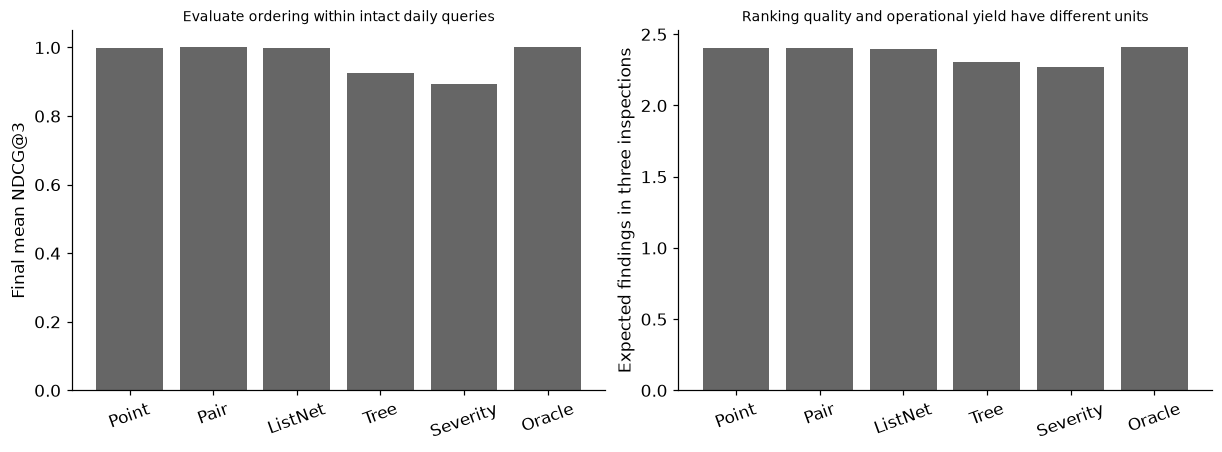

In [2]:
import xgboost as xgb
VERSIONS['xgboost']=xgb.__version__
def days(n,gr):
    x=gr.uniform(-1,1,(n,10,3));context=gr.choice([-1.,1.],n);features=np.concatenate([x,np.repeat(context[:,None,None],10,axis=1)],axis=2);latent=2*x[:,:,0]+1.2*x[:,:,1]*context[:,None]-.7*x[:,:,2];p=1/(1+np.exp(-latent));grade=np.digitize(latent,[-.7,0,.7]);return features,grade,p
SX,SY,SP=days(180,rng);DX,DY,DP=days(40,rng);FX,FY,FP=days(60,rng);initial=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,1)).state_dict();batches=np.random.default_rng(SEED+10).integers(0,180,(500,32));models={};last_losses={}
for objective in ['Pointwise','Pairwise','ListNet']:
    model=nn.Sequential(nn.Linear(4,16),nn.Tanh(),nn.Linear(16,1));model.load_state_dict(initial);optimizer=torch.optim.Adam(model.parameters(),lr=.01)
    for ids in batches:
        score=model(torch.tensor(SX[ids])).squeeze(-1);y=torch.tensor(SY[ids],dtype=torch.float64)
        if objective=='Pointwise':loss=nn.functional.mse_loss(score,y)
        elif objective=='Pairwise':delta=score[:,:,None]-score[:,None,:];ordered=y[:,:,None]>y[:,None,:];loss=nn.functional.softplus(-delta)[ordered].mean()
        else:loss=-(y.softmax(1)*score.log_softmax(1)).sum(1).mean()
        optimizer.zero_grad();loss.backward();optimizer.step()
    models[objective]=model;last_losses[objective]=float(loss.detach())
ranker=xgb.XGBRanker(objective='rank:ndcg',n_estimators=80,max_depth=3,learning_rate=.08,n_jobs=1,random_state=SEED);ranker.fit(SX.reshape(-1,4),SY.ravel(),qid=np.repeat(np.arange(180),10))
def scores(x,p):
    with torch.no_grad():out={name:model(torch.tensor(x)).squeeze(-1).numpy() for name,model in models.items()}
    out.update({'Tree NDCG':ranker.predict(x.reshape(-1,4)).reshape(-1,10),'Severity':x[:,:,0],'Oracle':p});return out
def evaluation(x,y,p):
    rows=[]
    for name,score in scores(x,p).items():
        order=np.argsort(-score,axis=1);chosen=order[:,:3];gain=2.**y-1;discount=1/np.log2(np.arange(2,5));dcg=(np.take_along_axis(gain,chosen,1)*discount).sum(1);ideal=(np.sort(gain,axis=1)[:,-3:][:,::-1]*discount).sum(1);ndcg=np.divide(dcg,ideal,out=np.ones_like(dcg),where=ideal>0);findings=np.take_along_axis(p,chosen,1).sum(1);rows.append({'model':name,'mean_NDCG_at3':float(ndcg.mean()),'mean_expected_findings_at3':float(findings.mean())})
    return rows
rows=evaluation(FX,FY,FP);dev=evaluation(DX,DY,DP);assert len(rows)==6 and all(0<=r['mean_NDCG_at3']<=1+1e-12 for r in rows);assert SX.shape[0]+DX.shape[0]+FX.shape[0]==280
RESULTS.update(source_days=180,development_days=40,final_days=60,candidates_per_day=10,daily_capacity=3,neural_updates_per_objective=500,batch_days=32,native_ranker_trees=80,losses_different_units=last_losses,final_metrics=rows,development_metrics=dev,development_used_for_selection=False,query_role_ids={'source':[0,179],'development':[1000,1039],'final':[2000,2059]})
display(pd.DataFrame(rows));fig,axes=plt.subplots(1,2,figsize=(11,4));labels=['Point','Pair','ListNet','Tree','Severity','Oracle'];axes[0].bar(range(6),[r['mean_NDCG_at3'] for r in rows],color='.4');axes[1].bar(range(6),[r['mean_expected_findings_at3'] for r in rows],color='.4')
for ax in axes:ax.set_xticks(range(6),labels);ax.tick_params(axis='x',rotation=20)
axes[0].set(ylabel='Final mean NDCG@3',ylim=(0,1.05),title='Evaluate ordering within intact daily queries');axes[1].set(ylabel='Expected findings in three inspections',title='Ranking quality and operational yield have different units');plt.show()


<a id="position-biased-feedback"></a>
 ## A nonresponse may mean the candidate was never examined
 Simulate 6,000 new daily lists. Display position follows the fixed ListNet score, and examination probability declines from 1 to 0.05 over ten positions. An observed response occurs only when both examination and a generated actionable finding occur. Analyze three predeclared severity bins using raw response rates and response/examination-probability weights. The exact examination mechanism is known because this is a simulator; a field log does not automatically identify it. If only the top three are ever displayed, the remaining candidates have zero display support and no weighting formula recovers their outcomes without extra assumptions. No logged response in this diagnostic fits or tunes a ranker.


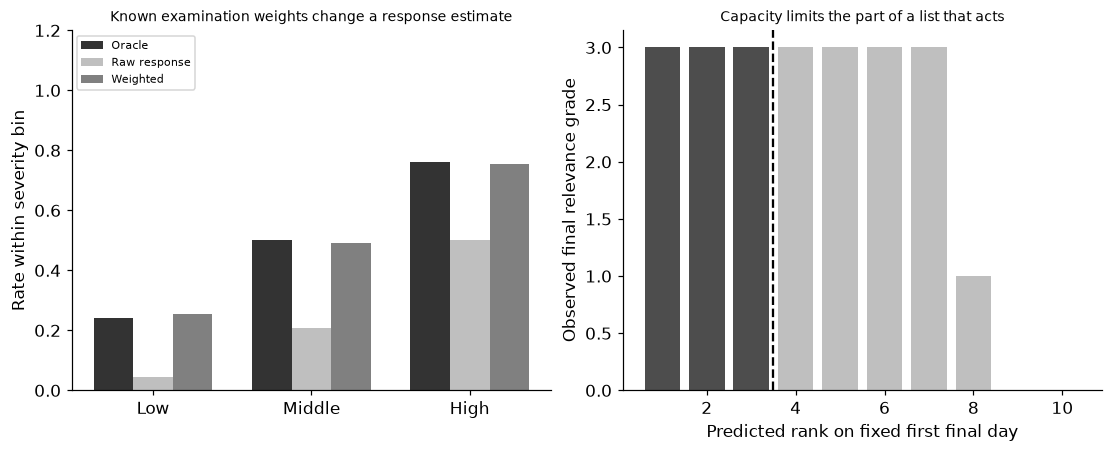

In [3]:
LX,LY,LP=days(6000,np.random.default_rng(SEED+100));score=scores(LX,LP)['ListNet'];order=np.argsort(-score,axis=1);position=np.argsort(order,axis=1);exam_by_position=np.array([1,.8,.6,.4,.25,.2,.15,.1,.08,.05]);exposure=exam_by_position[position];gr=np.random.default_rng(SEED+200);examined=gr.random(exposure.shape)<exposure;finding=gr.random(LP.shape)<LP;response=examined&finding;bins=np.digitize(LX[:,:,0],[-1/3,1/3]);bias=[]
for group in range(3):
    mask=bins==group;bias.append({'severity_bin':group,'candidate_records':int(mask.sum()),'oracle_expected_finding':float(LP[mask].mean()),'raw_response_rate':float(response[mask].mean()),'weighted_finding_estimate':float((response[mask]/exposure[mask]).mean())})
unsupported=int(np.sum(position>=3));assert exposure.min()==.05 and unsupported==6000*7 and len(bias)==3
RESULTS.update(position_feedback_days=6000,examination_probabilities=exam_by_position.tolist(),position_feedback=bias,never_displayed_records_under_top3_only=unsupported,top3_only_full_population_claim_refused=True,diagnostic_feedback_used_for_fitting=0)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for j,key in enumerate(['oracle_expected_finding','raw_response_rate','weighted_finding_estimate']):axes[0].bar(np.arange(3)+(j-1)*.25,[r[key] for r in bias],width=.25,color=['.2','.75','.5'][j],label=['Oracle','Raw response','Weighted'][j])
axes[0].set(xticks=range(3),xticklabels=['Low','Middle','High'],ylabel='Rate within severity bin',ylim=(0,1.2),title='Known examination weights change a response estimate');axes[0].legend(fontsize=7,loc='upper left');idx=np.argsort(-scores(FX,FP)['ListNet'][0]);axes[1].bar(range(1,11),FY[0,idx],color=['.3']*3+['.75']*7);axes[1].axvline(3.5,color='black',linestyle='--');axes[1].set(xlabel='Predicted rank on fixed first final day',ylabel='Observed final relevance grade',title='Capacity limits the part of a list that acts');plt.show()


In [4]:
summary={'example_id':'code_179','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual pointwise pairwise and ListNet top-one training losses', 'native pinned XGBRanker NDCG objective with sorted query groups', 'whole-day fit development and final separation', 'NDCG at capacity and expected findings compared independently', 'simulated position examination with known weighting and unsupported-display warning'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual pointwise pairwise and ListNet top-one training losses", "native pinned XGBRanker NDCG objective with sorted query groups", "whole-day fit development and final separation", "NDCG at capacity and expected findings compared independently", "simulated position examination with known weighting and unsupported-display warning"], "elapsed_seconds": 0.884, "example_id": "code_179", "hardware": "Darwin arm64 CPU", "results": {"batch_days": 32, "candidates_per_day": 10, "daily_capacity": 3, "development_days": 40, "development_metrics": [{"mean_NDCG_at3": 0.9942424951061589, "mean_expected_findings_at3": 2.378825886055907, "model": "Pointwise"}, {"mean_NDCG_at3": 1.0, "mean_expected_findings_at3": 2.379488185305359, "model": "Pairwise"}, {"mean_NDCG_at3": 0.996448785430263, "mean_expected_findings_at3": 2.3713405147662505, "model": "ListNet"}, {"mean_NDCG_at3": 0.9566696023588562, "mean_expected_findings_at3": 2.3043537436087376, "model